# Section 3 — Variable Selection and Model Development

**Assignment Section 3: 25 points.** This notebook organizes the existing variable selection and model development material without changing the analysis.

Authority: [professor’s assignment PDF](../project1-1%20%281%29.pdf), pp. 2–4; [exhaustive evidence audit](../docs/rubric_compliance_audit.md). Requirements are paraphrased in each subsection. Section 4 letters are organizational labels; the PDF uses diagnostic bullets. Historical numbered headings and forward-looking statements inside preserved cells refer to the original eight-notebook workflow; use this roadmap and the [cell migration audit](../docs/notebook_restructure_audit.md) for current locations. Historical compliance claims are preserved as source material; the new evidence audit supersedes them.

### Roadmap

- [3(a)](#rubric-3a)
- [3(b)](#rubric-3b)
- [3(c)](#rubric-3c)
- [3(d)](#rubric-3d)
- [3(e)](#rubric-3e)
- [3(f)](#rubric-3f)

### Dependencies and navigation

[Cleaning pipeline](cleaning/03_build_cross_section.ipynb) → [fixed cross-section](../data/processed/parking_cross_section.csv). Run each notebook with its own fresh Python kernel and working directory `notebooks/`. Sections 1 and 6 are narrative; sections 2–5 reload their own inputs. [Theory](01_economic_theory.ipynb) · [EDA](02_data_description_eda.ipynb) · [Models](03_variable_selection_models.ipynb) · [Diagnostics](04_diagnostics_robustness.ipynb) · [Results](05_results_interpretation.ipynb) · [Limitations](06_limitations_extensions.ipynb).

### Common candidate-sample setup

Selection starts from 12 encoded candidates and 4,016 complete cases. The model-comparison setup later reloads its own data; preserve that boundary.

# 05 — Variable Selection

Evaluate candidate predictors for the cross-sectional analysis using economic reasoning and the assignment requirements. Document the rationale for the variables and specifications you choose.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

parking = pd.read_csv(
    "../data/processed/parking_cross_section.csv"
)

print("Original observations:", len(parking))

parking = parking[parking["RateType"].isin(["FLAT", "TOD"])].copy()

print("Observations after excluding JUMP:", len(parking))


Original observations: 4139
Observations after excluding JUMP: 4060


In [2]:

variables = [
    "price_midpoint",
    "time_limit_hours",
    "population_density",
    "median_income",
    "nearby_restaurant_retail_count",
    "drive_alone_share",
    "RateType",
    "MeterType",
    "housing_density",
    "transit_share",
    "walk_share",
    "nearby_business_count"
]

y = parking["occupancy_rate"]

X = parking[variables].copy()

X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Explanatory variables:", X.columns.tolist())
print("Number of explanatory variables:", X.shape[1])


Explanatory variables: ['price_midpoint', 'time_limit_hours', 'population_density', 'median_income', 'nearby_restaurant_retail_count', 'drive_alone_share', 'housing_density', 'transit_share', 'walk_share', 'nearby_business_count', 'RateType_TOD', 'MeterType_Single-Space']
Number of explanatory variables: 12


In [3]:

data = pd.concat([y, X], axis=1)

print("Missing values:")
print(data.isnull().sum())

data = data.dropna()

y = data["occupancy_rate"]
X = data.drop(columns="occupancy_rate")

print("Final observations:", len(data))
print("Number of predictors:", X.shape[1])


Missing values:
occupancy_rate                     0
price_midpoint                     0
time_limit_hours                   0
population_density                 0
median_income                     44
nearby_restaurant_retail_count     0
drive_alone_share                  0
housing_density                    0
transit_share                      0
walk_share                         0
nearby_business_count              0
RateType_TOD                       0
MeterType_Single-Space             0
dtype: int64
Final observations: 4016
Number of predictors: 12


<a id="rubric-3a"></a>

## 3(a) Boruta Algorithm

**Requirement:** Apply Boruta and document parameters.

**Method:** Retain RandomForestRegressor(max_depth=5), automatic tree count, seed 10, two_step=True and verbose=2.

**Evidence:** Original 05 cells 6–8: 10 confirmed, income and meter type rejected; saved iterations through 30/100.

**Interpretation:** Boruta importance is not the same as an individual OLS p-value.

**Status: Complete.** Unspecified parameters use package defaults; Boruta 0.4.3 is pinned. Fresh execution requires that declared dependency.

Boruta is included in `requirements.txt`. I use the lecture’s random-forest selection settings below; installing packages is an environment setup step rather than part of the analysis.

In [6]:

from boruta import BorutaPy
from sklearn.ensemble import RandomForestRegressor

# Prepare data
parking_Y = y.values
parking_X = X.values.astype(np.float32)

# Random forest
rf = RandomForestRegressor(max_depth=5)

# Boruta
boruta = BorutaPy(
    rf,
    n_estimators="auto",
    verbose=2,
    random_state=10,
    two_step=True
)

boruta.fit(parking_X, parking_Y)

print("\nConfirmed:", list(X.columns[boruta.support_]))


Iteration: 	1 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0


Iteration: 	2 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0


Iteration: 	3 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0


Iteration: 	4 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0


Iteration: 	5 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0


...

Iteration: 	25 / 100
Confirmed: 	10
Tentative: 	1
Rejected: 	1


Iteration: 	26 / 100
Confirmed: 	10
Tentative: 	1
Rejected: 	1


Iteration: 	27 / 100
Confirmed: 	10
Tentative: 	1
Rejected: 	1


Iteration: 	28 / 100
Confirmed: 	10
Tentative: 	1
Rejected: 	1


Iteration: 	29 / 100
Confirmed: 	10
Tentative: 	0
Rejected: 	2


BorutaPy finished running.

Iteration: 	30 / 100
Confirmed: 	10
Tentative: 	0
Rejected: 	2

Confirmed: ['price_midpoint', 'time_limit_hours', 'population_density', 'nearby_restaurant_retail_count', 'drive_alone_share', 'housing_density', 'transit_share', 'walk_share', 'nearby_business_count', 'RateType_TOD']


In [7]:

boruta_keep = [
    "Confirmed" if c else "Tentative" if t else "Reject"
    for c, t in zip(boruta.support_, boruta.support_weak_)
]

boruta_features = zip(
    X.columns,
    boruta.ranking_,
    boruta_keep
)

for feat in boruta_features:
    print("Feature: {:<35} Rank: {}, Keep: {}".format(
        feat[0], feat[1], feat[2]
    ))


Feature: price_midpoint                      Rank: 1, Keep: Confirmed
Feature: time_limit_hours                    Rank: 1, Keep: Confirmed
Feature: population_density                  Rank: 1, Keep: Confirmed
Feature: median_income                       Rank: 2, Keep: Reject
Feature: nearby_restaurant_retail_count      Rank: 1, Keep: Confirmed
Feature: drive_alone_share                   Rank: 1, Keep: Confirmed
Feature: housing_density                     Rank: 1, Keep: Confirmed
Feature: transit_share                       Rank: 1, Keep: Confirmed
Feature: walk_share                          Rank: 1, Keep: Confirmed
Feature: nearby_business_count               Rank: 1, Keep: Confirmed
Feature: RateType_TOD                        Rank: 1, Keep: Confirmed
Feature: MeterType_Single-Space              Rank: 3, Keep: Reject


<a id="rubric-3b"></a>

## 3(b) Mallows Cp Criterion

**Requirement:** Apply Mallows Cp for variable selection.

**Method:** Retain the full-model variance estimate and exhaustive 4,095 nonempty subsets, including the best-eight display.

**Evidence:** Original 05 cells 9–13: minimum Cp 9.949599 (10 predictors), best-eight Cp 11.789.

**Interpretation:** The preferred seven-predictor model is not the global Cp minimum.

**Status: Complete.** 

In [8]:

full_model = sm.OLS(y, sm.add_constant(X)).fit()

print(full_model.summary())


                            OLS Regression Results                            
Dep. Variable:         occupancy_rate   R-squared:                       0.297
Model:                            OLS   Adj. R-squared:                  0.295
Method:                 Least Squares   F-statistic:                     140.7
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          8.50e-295
Time:                        21:07:35   Log-Likelihood:                 1608.0
No. Observations:                4016   AIC:                            -3190.
Df Residuals:                    4003   BIC:                            -3108.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const       

In [9]:

from itertools import combinations

sigma2 = full_model.mse_resid

cp_results = []

for k in range(1, len(X.columns) + 1):
    for cols in combinations(X.columns, k):
        model = sm.OLS(y, sm.add_constant(X[list(cols)])).fit()

        rss = sum(model.resid ** 2)
        p = k + 1

        cp = rss / sigma2 - (len(y) - 2 * p)

        cp_results.append({
            "Variables": cols,
            "Number of predictors": k,
            "Cp": cp,
            "Adjusted R2": model.rsquared_adj
        })

cp_results = pd.DataFrame(cp_results)

cp_results.sort_values("Cp").head(10)


,Variables,Number of predictors,Cp,Adjusted R2
4050,"(price_midpoint, time_limit_hours, population_...",10,9.949599,0.294709
3950,"(price_midpoint, population_density, nearby_re...",9,10.531400,0.294431
4090,"(price_midpoint, time_limit_hours, population_...",11,11.122981,0.294679
4069,"(price_midpoint, population_density, nearby_re...",10,11.578361,0.294423
4088,"(price_midpoint, time_limit_hours, population_...",11,11.773507,0.294564
3582,"(price_midpoint, population_density, nearby_re...",8,11.788981,0.294033
3867,"(price_midpoint, time_limit_hours, population_...",9,11.923251,0.294186
4067,"(price_midpoint, population_density, median_in...",10,12.257728,0.294303
3944,"(price_midpoint, population_density, nearby_re...",9,12.613759,0.294064
4044,"(price_midpoint, time_limit_hours, population_...",10,12.845720,0.294199


In [10]:

best_cp = cp_results.loc[
    cp_results.groupby("Number of predictors")["Cp"].idxmin()
]

best_cp[["Number of predictors", "Cp", "Adjusted R2"]].round(3)


,Number of predictors,Cp,Adjusted R2
0,1,786.957,0.157
13,2,413.784,0.222
93,3,231.578,0.255
414,4,82.641,0.281
956,5,55.239,0.286
1882,6,20.214,0.292
2861,7,17.199,0.293
3582,8,11.789,0.294
3950,9,10.531,0.294
4050,10,9.950,0.295


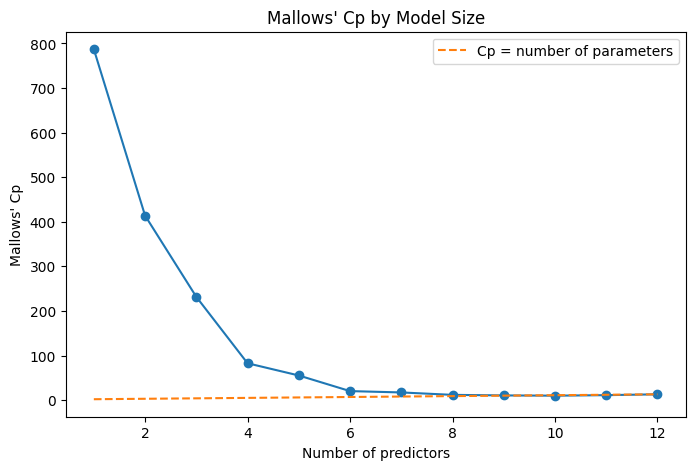

In [11]:

plt.figure(figsize=(8, 5))

plt.plot(
    best_cp["Number of predictors"],
    best_cp["Cp"],
    marker="o"
)

plt.plot(
    best_cp["Number of predictors"],
    best_cp["Number of predictors"] + 1,
    linestyle="--",
    label="Cp = number of parameters"
)

plt.xlabel("Number of predictors")
plt.ylabel("Mallows' Cp")
plt.title("Mallows' Cp by Model Size")
plt.legend()
plt.show()


In [12]:

best_8 = cp_results[
    cp_results["Number of predictors"] == 8
].sort_values("Cp").iloc[0]

print("Best 8-variable model:")
for variable in best_8["Variables"]:
    print(variable)

print("\nMallows' Cp:", round(best_8["Cp"], 3))
print("Adjusted R2:", round(best_8["Adjusted R2"], 3))


Best 8-variable model:
price_midpoint
population_density
nearby_restaurant_retail_count
housing_density
transit_share
walk_share
nearby_business_count
RateType_TOD

Mallows' Cp: 11.789
Adjusted R2: 0.294


<a id="rubric-3c"></a>

## 3(c) Variance Inflation Factors

**Requirement:** Check multicollinearity with VIF.

**Method:** Retain full and reduced VIF tables, selection comparison and preferred-model VIFs.

**Evidence:** Original 05 cells 4–5, 14–16.

**Interpretation:** Preferred slope VIFs are below two; the intercept VIF is not treated as a slope diagnostic.

**Status: Complete.** 

In [4]:

from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(X)

vif = pd.DataFrame()
vif["Variable"] = X_vif.columns
vif["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif.round(2)


,Variable,VIF
0,const,110.00
1,price_midpoint,1.71
2,time_limit_hours,1.16
3,population_density,11.98
4,median_income,2.08
5,nearby_restaurant_retail_count,5.91
6,drive_alone_share,2.96
7,housing_density,12.69
8,transit_share,2.32
9,walk_share,3.03


In [5]:

X_reduced = X.drop(columns=[
    "housing_density",
    "nearby_business_count"
])

X_vif_reduced = sm.add_constant(X_reduced)

vif_reduced = pd.DataFrame({
    "Variable": X_vif_reduced.columns,
    "VIF": [
        variance_inflation_factor(X_vif_reduced.values, i)
        for i in range(X_vif_reduced.shape[1])
    ]
})

vif_reduced.round(2)


,Variable,VIF
0,const,109.12
1,price_midpoint,1.64
2,time_limit_hours,1.13
3,population_density,1.18
4,median_income,2.03
5,nearby_restaurant_retail_count,1.75
6,drive_alone_share,2.79
7,transit_share,2.27
8,walk_share,2.49
9,RateType_TOD,1.23


In [13]:

comparison = pd.DataFrame({
    "Variable": X.columns,
    "Boruta Selected": boruta.support_,
    "Mallows Cp (8)": X.columns.isin(best_8["Variables"])
})

comparison = comparison.merge(
    vif[["Variable", "VIF"]],
    on="Variable",
    how="left"
)

comparison.round(2)


,Variable,Boruta Selected,Mallows Cp (8),VIF
0,price_midpoint,True,True,1.71
1,time_limit_hours,True,False,1.16
2,population_density,True,True,11.98
3,median_income,False,False,2.08
4,nearby_restaurant_retail_count,True,True,5.91
5,drive_alone_share,True,False,2.96
6,housing_density,True,True,12.69
7,transit_share,True,True,2.32
8,walk_share,True,True,3.03
9,nearby_business_count,True,True,6.68


In [14]:

selected_variables = [
    "price_midpoint",
    "time_limit_hours",
    "population_density",
    "nearby_restaurant_retail_count",
    "drive_alone_share",
    "transit_share",
    "RateType_TOD"
]

X_selected = X[selected_variables]

X_selected_vif = sm.add_constant(X_selected)

selected_vif = pd.DataFrame({
    "Variable": X_selected_vif.columns,
    "VIF": [
        variance_inflation_factor(X_selected_vif.values, i)
        for i in range(X_selected_vif.shape[1])
    ]
})

selected_vif.round(2)


,Variable,VIF
0,const,36.83
1,price_midpoint,1.62
2,time_limit_hours,1.11
3,population_density,1.09
4,nearby_restaurant_retail_count,1.67
5,drive_alone_share,1.67
6,transit_share,1.25
7,RateType_TOD,1.18


### Variable Selection Summary

I compared 12 candidate explanatory variables using VIF, Boruta, and Mallows' Cp.

Boruta confirmed 10 variables and rejected median income and meter type. Mallows' Cp showed that models with approximately 8–10 predictors provided similar adjusted R² values.

The initial VIF results showed substantial multicollinearity between population and housing density, as well as overlap between the two business-count variables. I retained population density and restaurant/retail count because they are directly relevant to parking demand.

My preferred specification contains seven explanatory variables: price, time limit, population density, restaurant/retail count, drive-alone commuting share, transit commuting share, and the TOD pricing indicator.

All seven predictors have VIF values below 2. I will use this specification as the main model and compare it with simpler OLS models in Notebook 06. These variables are associated with occupancy, but the analysis does not establish causal effects.

<a id="rubric-3d"></a>

## 3(d) Three Competing Regression Models

**Requirement:** Develop and economically/statistically justify Models 1, 2 and 3.

**Method:** Preserve the existing 1-, 3- and 7-predictor specifications and common sample.

**Evidence:** Original 06 cells 0–13.

**Interpretation:** Model 3 includes insignificant time limit and transit share and excludes some significant full-model terms.

**Status: Partial.** Original full-candidate regression has significant walk_share (p<0.001) and nearby_business_count (p<0.001), both omitted from Model 3. Model 3 time limit p=0.098 and transit share p=0.675 are not significant at 5%. The preserved specification is not all significant candidates or a significance-only subset.

# 06 — Regression Models

I compare the three OLS specifications developed from Notebook 05, using the same parking spaces in every model. I retain Models 1 and 3 and use a three-predictor Model 2 to meet the assignment. I compare fit, price coefficients and out-of-sample prediction before choosing a model to carry into diagnostics.

I reviewed `project1-1.pdf` and `Regression_Lecture0.ipynb`, `Regression_Lecture1.ipynb`, and `Regression_Lecture2.ipynb` in the local Downloads folder. The OLS, coefficient, dummy-variable, RMSE, and five-fold validation methods follow Lecture 1 (Sections 3.2, 4.1, and 6); multiple regression and AIC/BIC follow Lecture 2 (Sections 1.1 and 3.6). No new modeling method is introduced here.

## 1. Load and prepare the common sample

I load the unchanged Notebook 03 cross-section and retain FLAT and TOD meters, excluding the 79 JUMP spaces with incomparable price midpoints. I use the same 4,016 income-complete observations as Notebook 05 so changes across models reflect the controls rather than a changing sample. The 44 missing-income spaces are excluded for consistency with variable selection, even though none of these three models includes income.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

parking = pd.read_csv(
    "../data/processed/parking_cross_section.csv",
    dtype={"SpaceID": str, "GEOID": str}
)

print("Original observations:", len(parking))
print("JUMP observations excluded:", (parking["RateType"] == "JUMP").sum())

parking = parking[parking["RateType"].isin(["FLAT", "TOD"])].copy()

print("FLAT + TOD observations:", len(parking))

parking["RateType_TOD"] = (parking["RateType"] == "TOD").astype(int)

variables = [
    "occupancy_rate",
    "price_midpoint",
    "time_limit_hours",
    "population_density",
    "nearby_restaurant_retail_count",
    "drive_alone_share",
    "transit_share",
    "RateType_TOD",
    "median_income"
]

print("Missing values before the common-sample restriction:")
print(parking[variables].isnull().sum())

data = parking[variables].dropna().copy()

print("Common comparison observations:", len(data))
print("Unique parking spaces:", parking.loc[data.index, "SpaceID"].nunique())

print("Duplicate parking spaces:", parking.loc[data.index, "SpaceID"].duplicated().sum())
print("Census tracts:", parking.loc[data.index, "GEOID"].nunique())
print("Missing values in the comparison data:", data.isnull().sum().sum())

Original observations: 4139
JUMP observations excluded: 79
FLAT + TOD observations: 4060
Missing values before the common-sample restriction:
occupancy_rate                     0
price_midpoint                     0
time_limit_hours                   0
population_density                 0
nearby_restaurant_retail_count     0
drive_alone_share                  0
transit_share                      0
RateType_TOD                       0
median_income                     44
dtype: int64
Common comparison observations: 4016
Unique parking spaces: 4016
Duplicate parking spaces: 0
Census tracts: 45
Missing values in the comparison data: 0


The checks give 4,139 original spaces, 4,060 FLAT + TOD spaces, and 4,016 unique spaces in the common sample, with no remaining missing values in the comparison variables. `RateType_TOD` equals one for TOD meters and zero for FLAT meters, the reference category. The outcome and the seven predictor definitions are unchanged.

### Model 1 — Simple Regression with the Theoretically Most Important Predictor

## 2. Model 1: Price

I start with price alone to measure its unadjusted relationship with occupancy. `price_midpoint` is a stated hourly price for FLAT meters and a midpoint of hourly-rate endpoints for TOD meters, rather than the average payment made by drivers.

In [2]:

y = data["occupancy_rate"]

X1 = sm.add_constant(data[["price_midpoint"]])

model1 = sm.OLS(y, X1).fit()

print(model1.summary())


                            OLS Regression Results                            
Dep. Variable:         occupancy_rate   R-squared:                       0.157
Model:                            OLS   Adj. R-squared:                  0.157
Method:                 Least Squares   F-statistic:                     746.3
Date:                Sun, 25 Oct 2026   Prob (F-statistic):          7.41e-151
Time:                        18:52:12   Log-Likelihood:                 1243.8
No. Observations:                4016   AIC:                            -2484.
Df Residuals:                    4014   BIC:                            -2471.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.4237      0.005     84.

The price coefficient is 0.05451: a $1 higher price proxy is associated with about **5.45 percentage points** higher occupancy. Its conventional OLS p-value is below 0.001, but this is an association across locations, not evidence that raising prices causes occupancy to increase.

### Model 2 — Multiple Regression with 2–3 Key Predictors

## 3. Model 2: Add density and local activity

I add population density and nearby food-service/retail registrations to price to capture local demand conditions. This gives three predictors, meeting the assignment’s required 2–3-predictor middle model; time limit remains in Model 3.

In [3]:

X2 = sm.add_constant(data[[
    "price_midpoint",
    "population_density",
    "nearby_restaurant_retail_count"
]])

model2 = sm.OLS(y, X2).fit()

print(model2.summary())


                            OLS Regression Results                            
Dep. Variable:         occupancy_rate   R-squared:                       0.243
Model:                            OLS   Adj. R-squared:                  0.243
Method:                 Least Squares   F-statistic:                     430.5
Date:                Sun, 25 Oct 2026   Prob (F-statistic):          1.95e-242
Time:                        18:52:12   Log-Likelihood:                 1461.8
No. Observations:                4016   AIC:                            -2916.
Df Residuals:                    4012   BIC:                            -2890.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const       

The price coefficient rises to 0.05999, or about **6.00 percentage points per $1**, after adding these controls. Population density is positively associated with occupancy, while the registration-count coefficient is negative conditional on the other variables. Those conditional relationships can differ from the pairwise EDA correlations.

### Model 3 — Multiple Regression with All Statistically Significant Predictors

**Partial:** This is the rubric’s requested model description, not a claim that the unchanged seven-predictor model satisfies it.

## 4. Model 3: Preferred seven-variable specification

I add time limit, drive-alone share, transit share, and the TOD indicator to Model 2. This is the seven-variable specification chosen in Notebook 05 after reviewing economic relevance, Boruta, Mallows' Cp, and VIF; all seven were Boruta-confirmed and their selected-model VIFs were below two. It was a parsimonious choice, not the global minimum-Cp subset, and its performance still needs comparison here.

In [4]:

X3 = sm.add_constant(data[[
    "price_midpoint",
    "time_limit_hours",
    "population_density",
    "nearby_restaurant_retail_count",
    "drive_alone_share",
    "transit_share",
    "RateType_TOD"
]])

model3 = sm.OLS(y, X3).fit()

print(model3.summary())


                            OLS Regression Results                            
Dep. Variable:         occupancy_rate   R-squared:                       0.274
Model:                            OLS   Adj. R-squared:                  0.272
Method:                 Least Squares   F-statistic:                     215.7
Date:                Sun, 25 Oct 2026   Prob (F-statistic):          1.25e-272
Time:                        18:52:12   Log-Likelihood:                 1543.4
No. Observations:                4016   AIC:                            -3071.
Df Residuals:                    4008   BIC:                            -3020.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const       

The price coefficient remains positive at 0.05563. Time limit and transit share are not statistically significant at 5% in this specification; I keep them as specified rather than changing the model after seeing these p-values. All standard errors and confidence intervals here are conventional OLS estimates, with dependence and variance assumptions left for Notebook 07.

### Why the time-limit results changed

In the earlier four-predictor Model 2, the time-limit coefficient was **0.00365** (p = **0.216**), compared with **0.00488** (p = **0.098**) in Model 3 on the same **4,016 observations**. Adding drive-alone share, transit share and TOD changes the conditional estimate; its conventional standard error stays almost identical (**0.002947** versus **0.002948**), and checking the row indices and predictor lists finds no alignment error.

Neither estimate is significant at 5%; Model 3 only reaches 10% with conventional standard errors, which is weaker evidence. Notebook 07’s **HC1 p-value is 0.120**, so I do not treat the time-limit association as significant at either level under robust inference. The current Model 2 omits time limit to meet the rubric’s three-predictor requirement, not to obtain significance.

<a id="rubric-3e"></a>

## 3(e) AIC, BIC, Adjusted R², and Cross-Validation Comparison

**Requirement:** Compare all models using AIC, BIC, adjusted R² and cross-validation.

**Method:** Retain the complete in-sample comparison and shuffled five-fold, training-only prediction comparison (seed 10).

**Evidence:** Original 06 cells 14–19, 24–28.

**Interpretation:** Model 3 has the best metrics among these fixed specifications; selection and nearby-space leakage limits remain.

**Status: Complete.** 

## 5. Compare in-sample model performance

I compare all three models on the same outcome and observations, counting predictors without the intercept. Higher adjusted R² and lower AIC/BIC generally favor a model, while RMSE summarizes fitted errors in occupancy-rate units. This RMSE is in-sample fit, not held-out prediction performance.

In [5]:

comparison = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "Predictors": [1, 3, 7],
    "Adjusted R2": [
        model1.rsquared_adj,
        model2.rsquared_adj,
        model3.rsquared_adj
    ],
    "AIC": [
        model1.aic,
        model2.aic,
        model3.aic
    ],
    "BIC": [
        model1.bic,
        model2.bic,
        model3.bic
    ]
})

comparison["N"] = [int(model1.nobs), int(model2.nobs), int(model3.nobs)]
comparison["R2"] = [model1.rsquared, model2.rsquared, model3.rsquared]
comparison["In-sample RMSE"] = [
    np.sqrt(np.mean(model1.resid ** 2)),
    np.sqrt(np.mean(model2.resid ** 2)),
    np.sqrt(np.mean(model3.resid ** 2))
]
comparison = comparison[[
    "Model", "Predictors", "N", "R2", "Adjusted R2", "AIC", "BIC", "In-sample RMSE"
]]

comparison.round(5)


,Model,Predictors,N,R2,Adjusted R2,AIC,BIC,In-sample RMSE
0,Model 1,1,4016,0.15678,0.15657,-2483.67051,-2471.07443,0.17752
1,Model 2,3,4016,0.24350,0.24293,-2915.51726,-2890.32509,0.16815
2,Model 3,7,4016,0.27362,0.27235,-3070.71241,-3020.32808,0.16476


Adjusted R² rises from 0.157 to 0.243 to 0.272, and both AIC and BIC fall as controls are added. Negative AIC/BIC values are valid; the lower, more negative values are preferred on this common sample. Model 3 leads on these criteria, but I also check prediction rather than choosing it simply because it has more predictors.

## 6. Compare the price coefficients

I place the price estimates, conventional standard errors, p-values, and 95% confidence intervals side by side. A coefficient is measured in occupancy-rate units per dollar, so multiplying it by 100 gives the associated percentage-point difference. Scientific notation keeps very small p-values visible instead of rounding them to zero.

In [6]:

price_comparison = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "Price Coefficient": [
        model1.params["price_midpoint"],
        model2.params["price_midpoint"],
        model3.params["price_midpoint"]
    ],
    "P-value": [
        model1.pvalues["price_midpoint"],
        model2.pvalues["price_midpoint"],
        model3.pvalues["price_midpoint"]
    ]
})

price_comparison["Standard error"] = [
    model1.bse["price_midpoint"],
    model2.bse["price_midpoint"],
    model3.bse["price_midpoint"]
]
price_comparison["95% lower"] = [
    model1.conf_int().loc["price_midpoint", 0],
    model2.conf_int().loc["price_midpoint", 0],
    model3.conf_int().loc["price_midpoint", 0]
]
price_comparison["95% upper"] = [
    model1.conf_int().loc["price_midpoint", 1],
    model2.conf_int().loc["price_midpoint", 1],
    model3.conf_int().loc["price_midpoint", 1]
]
price_comparison = price_comparison[[
    "Model", "Price Coefficient", "Standard error", "P-value", "95% lower", "95% upper"
]]

price_comparison.style.format({
    "Price Coefficient": "{:.5f}", "Standard error": "{:.5f}",
    "P-value": "{:.3e}", "95% lower": "{:.5f}", "95% upper": "{:.5f}"
})


,Model,Price Coefficient,Standard error,P-value,95% lower,95% upper
0,Model 1,0.05451,0.00200,7.414e-151,0.05060,0.05843
1,Model 2,0.05999,0.00231,1.289e-137,0.05546,0.06452
2,Model 3,0.05563,0.00236,4.731e-115,0.05100,0.06026


The associated difference is **5.45**, **6.00**, and **5.56 percentage points per $1** in Models 1–3. All three estimates remain positive and significant at 5% under conventional OLS inference; adding the full controls does not reverse the sign. Demand-responsive pricing and omitted location characteristics remain plausible explanations, so this is not a causal price effect.

## 8. Compare five-fold prediction performance

Following Lecture 1, I use shuffled five-fold validation with seed 10 and the same folds for each model. `cross_val_score` fits a fresh `LinearRegression` with an intercept on each training fold and predicts only its held-out fold; it does not use the full-sample `model1`, `model2`, or `model3` fits. No scaling, imputation, or new predictor selection is performed in this comparison.

In [8]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression

folds = KFold(n_splits=5, shuffle=True, random_state=10)

cv1 = -cross_val_score(
    LinearRegression(), data[X1.columns.drop("const")], y,
    cv=folds, scoring="neg_root_mean_squared_error"
)
cv2 = -cross_val_score(
    LinearRegression(), data[X2.columns.drop("const")], y,
    cv=folds, scoring="neg_root_mean_squared_error"
)
cv3 = -cross_val_score(
    LinearRegression(), data[X3.columns.drop("const")], y,
    cv=folds, scoring="neg_root_mean_squared_error"
)

cv_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Model 1 RMSE": cv1,
    "Model 2 RMSE": cv2,
    "Model 3 RMSE": cv3
})
cv_results.round(5)

,Fold,Model 1 RMSE,Model 2 RMSE,Model 3 RMSE
0,1,0.17539,0.16599,0.16293
1,2,0.17974,0.17100,0.16667
2,3,0.17911,0.17081,0.16712
3,4,0.17685,0.16538,0.16425
4,5,0.17673,0.16787,0.16561


In [9]:
cv_summary = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "Mean CV RMSE": [cv1.mean(), cv2.mean(), cv3.mean()],
    "SD across folds": [cv1.std(ddof=1), cv2.std(ddof=1), cv3.std(ddof=1)]
})
cv_summary.round(5)

,Model,Mean CV RMSE,SD across folds
0,Model 1,0.17756,0.00181
1,Model 2,0.16821,0.00263
2,Model 3,0.16532,0.00173


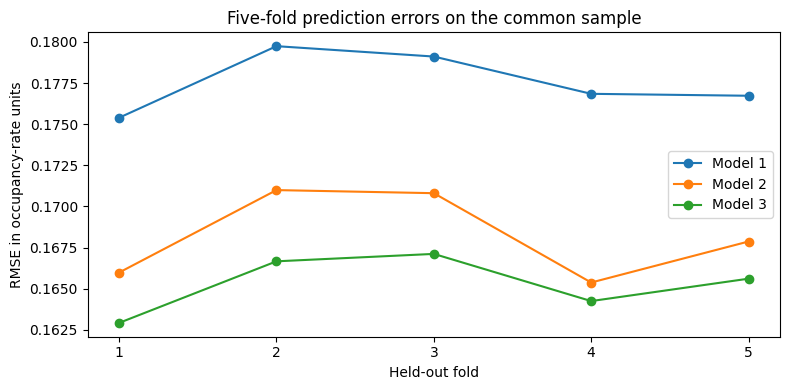

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, 6), cv1, marker="o", label="Model 1")
plt.plot(range(1, 6), cv2, marker="o", label="Model 2")
plt.plot(range(1, 6), cv3, marker="o", label="Model 3")
plt.xticks(range(1, 6))
plt.xlabel("Held-out fold")
plt.ylabel("RMSE in occupancy-rate units")
plt.title("Five-fold prediction errors on the common sample")
plt.legend()
plt.tight_layout()
plt.show()

Mean held-out RMSE falls from **0.17756** to **0.16821** to **0.16532**. Model 3 performs best in each of these five folds; its mean error is about **16.53 percentage points in root-mean-square terms**, an improvement of about **0.29 percentage points** over Model 2. The fold standard deviations describe variation across these splits, not standard errors for a formal test of model differences.

The 4,016 spaces lie in 45 Census tracts, so random folds can put neighboring spaces and the same tract in training and test data. This evaluates prediction for held-out spaces from the observed setting, not entirely new neighborhoods. It also evaluates the three fixed specifications rather than the full variable-selection process; Notebook 05 used the common sample before this comparison, so these are not untouched post-selection validation results.

<a id="rubric-3f"></a>

## 3(f) Final Model Selection and Justification

**Requirement:** Select the final model with detailed economic/statistical justification.

**Method:** Retain the comparison winners and economic rationale alongside the significance discrepancy.

**Evidence:** Original 06 cells 29–34; original 08 cells 11–12.

**Interpretation:** The seven-predictor model is preferred among the three compared, with modest prediction gains.

**Status: Complete.** 

## 9. Choose a model to carry into diagnostics

I combine the fit and held-out error summaries before making a provisional choice. The criteria evaluate different tradeoffs, so I show their preferred models separately. The comparison is conditional on the same 4,016 observations and the three specified models.

In [11]:
final_comparison = comparison.merge(cv_summary, on="Model", validate="one_to_one")
final_comparison.round(5)

,Model,Predictors,N,R2,Adjusted R2,AIC,BIC,In-sample RMSE,Mean CV RMSE,SD across folds
0,Model 1,1,4016,0.15678,0.15657,-2483.67051,-2471.07443,0.17752,0.17756,0.00181
1,Model 2,3,4016,0.24350,0.24293,-2915.51726,-2890.32509,0.16815,0.16821,0.00263
2,Model 3,7,4016,0.27362,0.27235,-3070.71241,-3020.32808,0.16476,0.16532,0.00173


In [12]:
ranked = final_comparison.set_index("Model")
winners = pd.Series({
    "Highest adjusted R2": ranked["Adjusted R2"].idxmax(),
    "Lowest AIC": ranked["AIC"].idxmin(),
    "Lowest BIC": ranked["BIC"].idxmin(),
    "Lowest mean CV RMSE": ranked["Mean CV RMSE"].idxmin()
}, name="Preferred model")
winners

Highest adjusted R2    Model 3
Lowest AIC             Model 3
Lowest BIC             Model 3
Lowest mean CV RMSE    Model 3
Name: Preferred model, dtype: object

Model 3 has the highest adjusted R² (**0.27235**), lowest AIC (**−3,070.71**), lowest BIC (**−3,020.33**), and lowest mean CV RMSE (**0.16532**). It explains about **27.36%** of the sample variation in occupancy, so substantial variation remains unexplained. The price estimate stays positive and conventionally significant in every model.

I carry Model 3 forward because it improves the fit criteria and prediction in this comparison, not simply because it has seven predictors. Its prediction gain over Model 2 is modest, and time limit and transit share remain individually insignificant at 5%. This is a provisional choice for diagnostics, not a claim that the assumptions hold or that every included variable is statistically significant.

## 10. Limitations, assignment check, and next steps

The outcome is August 2025 occupancy, while prices and business registrations come from October 2026. TOD midpoint summarizes hourly-rate endpoints rather than actual payments, and prices may respond to demand, creating endogeneity. Registration counts also need not represent unique storefronts or businesses active during the outcome month.

Several spaces share tracts and nearby demand conditions, so the conventional standard errors need further examination. Large condition numbers in the summaries can reflect differing variable units as well as collinearity; they are not a diagnosis by themselves, and Notebook 05's selected-model VIFs were below two. OLS predictions are not constrained to the occupancy interval of zero to one.

Notebook 07 will examine residuals, regression assumptions, influential observations, and robustness. Planned sensor comparisons cover 12/24/48-hour maximum intervals, 20/25/28 active days, and Sunday-reporting differences; none of those datasets or diagnostics is rebuilt here. The five-fold comparison above already supplies the requested initial held-out prediction check and need not be repeated without a reason.

### Assignment checklist

| Requirement | Status and location |
|---|---|
| 500+ cross-sectional observations and five potential predictors | 4,016 spaces and seven preferred predictors; Notebooks 03–06 |
| Sources, definitions, descriptive statistics, EDA and missingness | Notebooks 01–04; remaining predictor Q-Q/density plots and Profiling discussion completed in Notebook 08 |
| Boruta, Mallows’ Cp and VIF | Notebook 05 |
| Three models with one, 2–3, and a broader set of predictors | Corrected here to 1, 3 and 7 predictors on the same sample |
| Adjusted R², AIC, BIC and five-fold prediction | Completed here; fixed folds, training-only fits, seed 10 |
| Coefficients, uncertainty and economic interpretation | Conventional inference here; HC1 comparison in Notebook 07 and final HC1 presentation in Notebook 08 |
| Residual, normality, variance, RESET and influence checks | Notebook 07; DFBETAS remains outstanding because no example was found in the lectures |
| Bootstrap with 1,000 replications | Notebook 07, all Model 3 coefficients |
| Economic literature, final interpretation and limitations | Notebook 08 |
| PDF/HTML group report with names and Python source | Submission packaging remains outstanding |

Model 3 retains the seven predictors chosen in Notebook 05. Time limit and transit share are not individually significant at 5%; the model includes the significant terms within this specification, but it is not a significance-only subset of all candidates. I retain it for the stated economic and selection rationale and comparison criteria, rather than claim that every included predictor is significant. This interpretation of the rubric’s significance-based wording should be checked before submission.

All statistical methods here follow Lectures 1–2. The source data and primary Model 3 remain unchanged.

In [ ]:
# Bridge the retained selection list to the moved results summary.
predictors = selected_variables.copy()


## 4. Variable-selection summary

Notebook 05 compares 12 encoded candidates with Boruta, Mallows’ Cp and VIF. Boruta confirms 10 and rejects income and meter type; the lowest Cp is about **9.950** with ten predictors, while the best eight-predictor subset has Cp **11.789** and adjusted R² about **0.294**. The final seven are a simpler economically motivated choice, not the global Cp minimum.

I retain population density and food-service/retail count instead of their strongly correlated alternatives. Each of the seven preferred predictors has VIF below 2, excluding the intercept. I reuse the executed selection results rather than rerun Boruta and all 4,095 subsets here; time limit and transit share are retained for this primary specification even though their final individual tests are insignificant.

In [6]:
pd.DataFrame({
    "Preferred predictor": predictors,
    "Reason": ["Stated price proxy", "Parking time rule", "Residential demand intensity",
               "Nearby commercial activity", "Resident driving pattern", "Resident transit pattern",
               "TOD pricing structure relative to FLAT"]
})

,Preferred predictor,Reason
0,price_midpoint,Stated price proxy
1,time_limit_hours,Parking time rule
2,population_density,Residential demand intensity
3,nearby_restaurant_retail_count,Nearby commercial activity
4,drive_alone_share,Resident driving pattern
5,transit_share,Resident transit pattern
6,RateType_TOD,TOD pricing structure relative to FLAT


### Supporting Evidence — Original coefficient interpretation

Retained in its original execution context; final HC1 interpretation is in Section 5.

## 7. Interpret Model 3

I report each coefficient with its uncertainty, then use changes that are easier to interpret for density, registrations, and commuting shares. These comparisons hold the other included variables constant. Statistical significance does not establish causality or tell us whether a magnitude is economically large.

In [7]:
coefficient_table = pd.DataFrame({
    "Coefficient": model3.params,
    "Standard error": model3.bse,
    "P-value": model3.pvalues,
    "95% lower": model3.conf_int()[0],
    "95% upper": model3.conf_int()[1]
})
coefficient_table.index.name = "Variable"

coefficient_table.style.format({
    "Coefficient": "{:.6g}", "Standard error": "{:.6g}",
    "P-value": "{:.3e}", "95% lower": "{:.6g}", "95% upper": "{:.6g}"
})

,Coefficient,Standard error,P-value,95% lower,95% upper
Variable,,,,,
const,0.456337,0.0157939,6.470e-167,0.425373,0.487302
price_midpoint,0.0556328,0.00236136,4.731e-115,0.0510033,0.0602624
time_limit_hours,0.00487929,0.00294796,9.797e-02,-0.000900361,0.0106589
population_density,4.57052e-06,2.21771e-07,8.803e-90,4.13573e-06,5.00531e-06
nearby_restaurant_retail_count,-0.000321282,2.29852e-05,2.189e-43,-0.000366346,-0.000276218
drive_alone_share,-0.198101,0.0208314,3.195e-21,-0.238942,-0.15726
transit_share,0.0196471,0.0468362,6.749e-01,-0.072178,0.111472
RateType_TOD,0.0330042,0.00731608,6.631e-06,0.0186606,0.0473478


- **Price:** a $1 higher proxy is associated with **5.56 percentage points** higher occupancy (95% CI: **5.10 to 6.03**). This is a sizeable conditional difference, with the timing and endogeneity qualifications already noted.
- **Time limit:** an additional permitted hour is associated with **0.49 percentage points** higher occupancy, but the interval spans zero (−0.09 to 1.07; p = 0.098).
- **Population density:** an additional **1,000 people per square mile** is associated with **0.46 percentage points** higher occupancy (95% CI: 0.41 to 0.50).
- **Food-service/retail activity:** **100 additional registrations within 0.25 miles** are associated with **3.21 percentage points lower** occupancy (95% CI: −3.66 to −2.76). This conditional association does not mean that opening businesses reduces parking demand.

- **Drive-alone share:** a **10-percentage-point increase** is associated with **1.98 percentage points lower** occupancy (95% CI: −2.39 to −1.57).
- **Transit share:** a **10-percentage-point increase** is associated with **0.20 percentage points higher** occupancy, with substantial uncertainty (95% CI: −0.72 to 1.11; p = 0.675). This is not clear evidence of a nonzero conditional relationship.
- **TOD indicator:** TOD spaces have **3.30 percentage points higher** predicted occupancy than FLAT spaces with the same included covariates (95% CI: 1.87 to 4.73).

The intercept is 0.45634, the fitted occupancy for a FLAT meter when all numeric predictors are zero. That combination is outside the observed support, so the intercept has little standalone economic meaning.

## Section Summary and Rubric Coverage

Boruta, Cp, VIF, comparisons and final justification have saved evidence. 3(d) is Partial: the unchanged seven-variable Model 3 does not include all significant full-candidate terms and retains insignificant terms. No model was changed.

Preserved outputs record earlier execution, not a claim that this migrated workflow has been rerun. See [validation evidence](../docs/notebook_validation_summary.md) for fresh execution results and blockers, and the [rubric audit](../docs/rubric_compliance_audit.md) for evidence-backed component status.